# 🌾 Prédiction de la Sécheresse Agricole en Tunisie
## Notebook 02 — Preprocessing & Modélisation

**Auteure :** Souha Guezguez  
**Filière :** 4ème cycle Data Science & IA  
**Année :** 2025 / 2026  

---

### Plan du notebook
1. Chargement des données
2. Preprocessing
3. Feature Engineering
4. Préparation Train/Test
5. Modélisation (4 algorithmes)
6. Évaluation et comparaison
7. Optimisation des hyperparamètres
8. Importance des features
9. Sauvegarde du meilleur modèle
10. Conclusion

---
## 1. 📦 Importation des librairies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
import os

# Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV

# Modeles
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize']   = (12, 5)
plt.rcParams['font.size']        = 11
plt.rcParams['axes.titleweight'] = 'bold'
sns.set_style('whitegrid')

os.makedirs('../models', exist_ok=True)

print('Librairies importees avec succes !')

Librairies importees avec succes !


---
## 2. 📂 Chargement des données

In [2]:
df = pd.read_csv('../data/dataset_secheresse_tunisie.csv', parse_dates=['date'])

# Colonnes temporelles
df['annee'] = df['date'].dt.year
df['mois']  = df['date'].dt.month

print(f'Dataset charge : {df.shape[0]:,} lignes x {df.shape[1]} colonnes')
print(f'Colonnes : {df.columns.tolist()}')
df.head()

Dataset charge : 122,712 lignes x 18 colonnes
Colonnes : ['date', 'precipitations_mm', 'temperature_moy', 'temperature_max', 'temperature_min', 'humidite_pct', 'vent_ms', 'rayonnement_solaire', 'gouvernorat', 'region', 'latitude', 'longitude', 'cumul_mensuel', 'cumul_rolling', 'spi', 'risque_secheresse', 'annee', 'mois']


,date,precipitations_mm,temperature_moy,temperature_max,temperature_min,humidite_pct,vent_ms,rayonnement_solaire,gouvernorat,region,latitude,longitude,cumul_mensuel,cumul_rolling,spi,risque_secheresse,annee,mois
0,2010-01-01,0.92,13.84,17.34,11.00,66.50,7.14,10.23,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010,1
1,2010-01-02,1.64,13.74,16.42,11.59,72.61,5.96,6.84,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010,1
2,2010-01-03,0.02,12.83,16.77,9.63,74.80,2.58,9.39,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010,1
3,2010-01-04,0.01,11.65,16.71,7.91,71.33,2.14,5.96,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010,1
4,2010-01-05,0.02,12.64,18.78,7.35,71.62,2.40,10.29,Tunis,Nord,36.82,10.17,63.94,NaN,NaN,NaN,2010,1


---
## 3. 🧹 Preprocessing

### 3.1 Suppression des valeurs manquantes

In [3]:
print(f'Avant nettoyage : {len(df):,} lignes')
print(f'Valeurs manquantes :\n{df.isnull().sum()}')

# Supprimer les lignes sans variable cible (les 3 premiers mois par gouvernorat)
df = df.dropna(subset=['risque_secheresse', 'spi'])

# Supprimer les doublons
df = df.drop_duplicates()

# Convertir la cible en entier
df['risque_secheresse'] = df['risque_secheresse'].astype(int)

print(f'\nApres nettoyage  : {len(df):,} lignes')
print(f'Lignes supprimees : {122712 - len(df):,}')

Avant nettoyage : 122,712 lignes
Valeurs manquantes :
date                      0
precipitations_mm         0
temperature_moy           0
temperature_max           0
temperature_min           0
humidite_pct              0
vent_ms                   0
rayonnement_solaire       0
gouvernorat               0
region                    0
latitude                  0
longitude                 0
cumul_mensuel             0
cumul_rolling          1416
spi                    1416
risque_secheresse      1416
annee                     0
mois                      0
dtype: int64

Apres nettoyage  : 121,296 lignes
Lignes supprimees : 1,416


### 3.2 Encodage des variables catégorielles

In [4]:
# Encodage de la region (Nord=2, Centre=0, Sud=1)
le_region = LabelEncoder()
df['region_enc'] = le_region.fit_transform(df['region'])

# Encodage du gouvernorat
le_gouv = LabelEncoder()
df['gouvernorat_enc'] = le_gouv.fit_transform(df['gouvernorat'])

print('Encodage region :')
for i, label in enumerate(le_region.classes_):
    print(f'  {label} → {i}')

print(f'\nNombre de gouvernorats encodes : {df["gouvernorat_enc"].nunique()}')

Encodage region :
  Centre → 0
  Nord → 1
  Sud → 2

Nombre de gouvernorats encodes : 24


### 3.3 Vérification du déséquilibre des classes

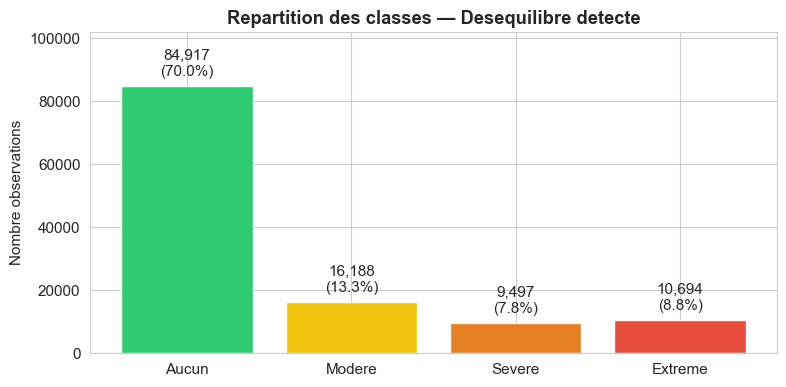

Solution : class_weight="balanced" dans tous les modeles


In [5]:
labels  = {0:'Aucun', 1:'Modere', 2:'Severe', 3:'Extreme'}
colors  = ['#2ecc71','#f1c40f','#e67e22','#e74c3c']
counts  = df['risque_secheresse'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar([labels[i] for i in counts.index], counts.values, color=colors)
ax.bar_label(bars, labels=[f'{v:,}\n({v/len(df)*100:.1f}%)' for v in counts.values], padding=5)
ax.set_title('Repartition des classes — Desequilibre detecte')
ax.set_ylabel('Nombre observations')
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.show()

print('Solution : class_weight="balanced" dans tous les modeles')

---
## 4. ⚙️ Feature Engineering

In [6]:
df = df.sort_values(['gouvernorat', 'date']).reset_index(drop=True)

# Rolling mean des precipitations (7 jours et 30 jours)
df['precip_rolling_7j'] = (
    df.groupby('gouvernorat')['precipitations_mm']
    .transform(lambda x: x.rolling(7,  min_periods=1).mean())
)
df['precip_rolling_30j'] = (
    df.groupby('gouvernorat')['precipitations_mm']
    .transform(lambda x: x.rolling(30, min_periods=1).mean())
)

# Saison (1=Hiver, 2=Printemps, 3=Ete, 4=Automne)
def get_saison(mois):
    if mois in [12, 1, 2]:  return 1  # Hiver
    elif mois in [3, 4, 5]: return 2  # Printemps
    elif mois in [6, 7, 8]: return 3  # Ete
    else:                   return 4  # Automne

df['saison'] = df['mois'].apply(get_saison)

# Amplitude thermique
df['amplitude_thermique'] = df['temperature_max'] - df['temperature_min']

# Jour sec (precipitations = 0)
df['jour_sec'] = (df['precipitations_mm'] == 0).astype(int)

print('Nouvelles features creees :')
print('  - precip_rolling_7j   : moyenne mobile 7 jours')
print('  - precip_rolling_30j  : moyenne mobile 30 jours')
print('  - saison              : 1=Hiver, 2=Printemps, 3=Ete, 4=Automne')
print('  - amplitude_thermique : temperature_max - temperature_min')
print('  - jour_sec            : 1 si precipitations = 0')
print(f'\nDataset final : {df.shape[0]:,} lignes x {df.shape[1]} colonnes')

Nouvelles features creees :
  - precip_rolling_7j   : moyenne mobile 7 jours
  - precip_rolling_30j  : moyenne mobile 30 jours
  - saison              : 1=Hiver, 2=Printemps, 3=Ete, 4=Automne
  - amplitude_thermique : temperature_max - temperature_min
  - jour_sec            : 1 si precipitations = 0

Dataset final : 121,296 lignes x 25 colonnes


---
## 5. ✂️ Séparation Train / Test

In [7]:
# Features selectionnees
FEATURES = [
    'precipitations_mm', 'temperature_moy', 'temperature_max',
    'temperature_min',   'humidite_pct',    'vent_ms',
    'precip_rolling_7j', 'precip_rolling_30j',
    'amplitude_thermique', 'jour_sec',
    'saison', 'mois', 'region_enc', 'gouvernorat_enc'
]

TARGET = 'risque_secheresse'

X = df[FEATURES]
y = df[TARGET]

# Split 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Features selectionnees : {len(FEATURES)}')
print(f'X_train : {X_train.shape}')
print(f'X_test  : {X_test.shape}')
print(f'\nRepartition y_train :')
print(y_train.value_counts().sort_index())

Features selectionnees : 14
X_train : (97036, 14)
X_test  : (24260, 14)

Repartition y_train :
risque_secheresse
0    67933
1    12950
2     7598
3     8555
Name: count, dtype: int64


In [8]:
# Normalisation (StandardScaler)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Sauvegarder le scaler pour l'application Streamlit
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(le_region, '../models/le_region.pkl')
joblib.dump(le_gouv,   '../models/le_gouvernorat.pkl')

print('Normalisation appliquee (StandardScaler)')
print('Scaler et encodeurs sauvegardes dans models/')

Normalisation appliquee (StandardScaler)
Scaler et encodeurs sauvegardes dans models/


---
## 6. 🤖 Modélisation — 4 algorithmes

### 6.1 Logistic Regression

In [9]:
print('Entrainement Logistic Regression...')

lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)

acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr  = f1_score(y_test, y_pred_lr, average='weighted')

print(f'Accuracy : {acc_lr:.4f}')
print(f'F1-Score : {f1_lr:.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_lr,
      target_names=['Aucun','Modere','Severe','Extreme']))

Entrainement Logistic Regression...
Accuracy : 0.6092
F1-Score : 0.6478

Rapport de classification :
              precision    recall  f1-score   support

       Aucun       0.93      0.69      0.79     16984
      Modere       0.22      0.30      0.25      3238
      Severe       0.15      0.23      0.18      1899
     Extreme       0.38      0.75      0.50      2139

    accuracy                           0.61     24260
   macro avg       0.42      0.49      0.43     24260
weighted avg       0.72      0.61      0.65     24260



### 6.2 Decision Tree

In [10]:
print('Entrainement Decision Tree...')

dt = DecisionTreeClassifier(
    max_depth=10,
    class_weight='balanced',
    random_state=42
)
dt.fit(X_train_sc, y_train)
y_pred_dt = dt.predict(X_test_sc)

acc_dt = accuracy_score(y_test, y_pred_dt)
f1_dt  = f1_score(y_test, y_pred_dt, average='weighted')

print(f'Accuracy : {acc_dt:.4f}')
print(f'F1-Score : {f1_dt:.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_dt,
      target_names=['Aucun','Modere','Severe','Extreme']))

Entrainement Decision Tree...
Accuracy : 0.7052
F1-Score : 0.7349

Rapport de classification :
              precision    recall  f1-score   support

       Aucun       0.97      0.74      0.84     16984
      Modere       0.37      0.56      0.45      3238
      Severe       0.35      0.63      0.45      1899
     Extreme       0.50      0.76      0.60      2139

    accuracy                           0.71     24260
   macro avg       0.55      0.67      0.59     24260
weighted avg       0.80      0.71      0.73     24260



### 6.3 Random Forest

In [11]:
print('Entrainement Random Forest (patientez ~1 minute)...')

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_sc, y_train)
y_pred_rf = rf.predict(X_test_sc)

acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf  = f1_score(y_test, y_pred_rf, average='weighted')

print(f'Accuracy : {acc_rf:.4f}')
print(f'F1-Score : {f1_rf:.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_rf,
      target_names=['Aucun','Modere','Severe','Extreme']))

Entrainement Random Forest (patientez ~1 minute)...
Accuracy : 0.8304
F1-Score : 0.8360

Rapport de classification :
              precision    recall  f1-score   support

       Aucun       0.96      0.89      0.92     16984
      Modere       0.61      0.60      0.61      3238
      Severe       0.57      0.64      0.61      1899
     Extreme       0.59      0.86      0.70      2139

    accuracy                           0.83     24260
   macro avg       0.68      0.75      0.71     24260
weighted avg       0.85      0.83      0.84     24260



### 6.4 XGBoost

In [12]:
print('Entrainement XGBoost (patientez ~1 minute)...')

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train_sc, y_train)
y_pred_xgb = xgb.predict(X_test_sc)

acc_xgb = accuracy_score(y_test, y_pred_xgb)
f1_xgb  = f1_score(y_test, y_pred_xgb, average='weighted')

print(f'Accuracy : {acc_xgb:.4f}')
print(f'F1-Score : {f1_xgb:.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_xgb,
      target_names=['Aucun','Modere','Severe','Extreme']))

Entrainement XGBoost (patientez ~1 minute)...
Accuracy : 0.8002
F1-Score : 0.7774

Rapport de classification :
              precision    recall  f1-score   support

       Aucun       0.87      0.96      0.91     16984
      Modere       0.57      0.32      0.41      3238
      Severe       0.53      0.24      0.33      1899
     Extreme       0.56      0.75      0.64      2139

    accuracy                           0.80     24260
   macro avg       0.63      0.57      0.57     24260
weighted avg       0.78      0.80      0.78     24260



---
## 7. 📊 Comparaison des modèles

In [13]:
# Tableau comparatif
resultats = pd.DataFrame({
    'Modele':   ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost'],
    'Accuracy': [acc_lr, acc_dt, acc_rf, acc_xgb],
    'F1-Score': [f1_lr,  f1_dt,  f1_rf,  f1_xgb],
})
resultats = resultats.sort_values('F1-Score', ascending=False).reset_index(drop=True)
resultats['Accuracy'] = resultats['Accuracy'].map('{:.4f}'.format)
resultats['F1-Score'] = resultats['F1-Score'].map('{:.4f}'.format)
print(resultats.to_string(index=False))

             Modele Accuracy F1-Score
      Random Forest   0.8304   0.8360
            XGBoost   0.8002   0.7774
      Decision Tree   0.7052   0.7349
Logistic Regression   0.6092   0.6478


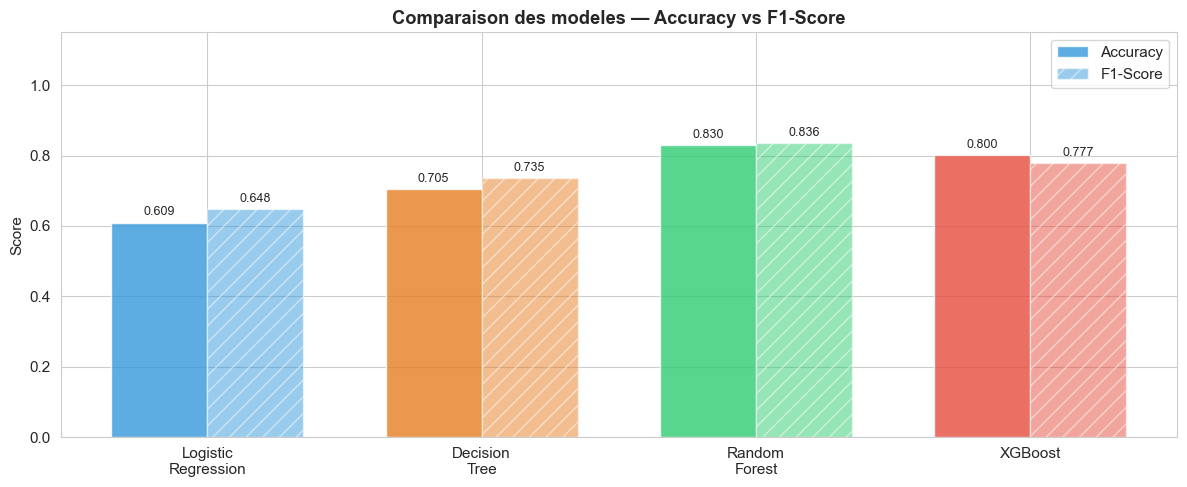

In [14]:
# Graphique de comparaison
modeles   = ['Logistic\nRegression', 'Decision\nTree', 'Random\nForest', 'XGBoost']
accs      = [acc_lr, acc_dt, acc_rf, acc_xgb]
f1s       = [f1_lr,  f1_dt,  f1_rf,  f1_xgb]
colors    = ['#3498db', '#e67e22', '#2ecc71', '#e74c3c']

x      = np.arange(len(modeles))
width  = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, accs, width, label='Accuracy', color=colors, alpha=0.8)
bars2 = ax.bar(x + width/2, f1s,  width, label='F1-Score', color=colors, alpha=0.5,
               hatch='//')
ax.bar_label(bars1, fmt='%.3f', padding=3, fontsize=9)
ax.bar_label(bars2, fmt='%.3f', padding=3, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(modeles)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.set_title('Comparaison des modeles — Accuracy vs F1-Score')
ax.legend()
plt.tight_layout()
plt.savefig('../data/comparaison_modeles.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 8. 🔧 Optimisation des hyperparamètres (meilleur modèle)

In [15]:
print('Optimisation Random Forest avec RandomizedSearchCV...')
print('(patientez 2-3 minutes)')

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth':    [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 4],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring='f1_weighted',
    random_state=42,
    verbose=1
)
rf_search.fit(X_train_sc, y_train)

print(f'\nMeilleurs hyperparametres : {rf_search.best_params_}')
print(f'Meilleur F1 (CV)          : {rf_search.best_score_:.4f}')

Optimisation Random Forest avec RandomizedSearchCV...
(patientez 2-3 minutes)
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Meilleurs hyperparametres : {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 20}
Meilleur F1 (CV)          : 0.8528


In [16]:
# Evaluation du modele optimise
best_model    = rf_search.best_estimator_
y_pred_best   = best_model.predict(X_test_sc)
acc_best      = accuracy_score(y_test, y_pred_best)
f1_best       = f1_score(y_test, y_pred_best, average='weighted')

print(f'Modele optimise — Accuracy : {acc_best:.4f}')
print(f'Modele optimise — F1-Score : {f1_best:.4f}')
print(f'Amelioration F1  : +{(f1_best - f1_rf):.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_best,
      target_names=['Aucun','Modere','Severe','Extreme']))

Modele optimise — Accuracy : 0.8736
Modele optimise — F1-Score : 0.8734
Amelioration F1  : +0.0374

Rapport de classification :
              precision    recall  f1-score   support

       Aucun       0.95      0.94      0.94     16984
      Modere       0.74      0.64      0.69      3238
      Severe       0.70      0.70      0.70      1899
     Extreme       0.68      0.87      0.76      2139

    accuracy                           0.87     24260
   macro avg       0.77      0.79      0.77     24260
weighted avg       0.88      0.87      0.87     24260



---
## 9. 📉 Matrice de confusion

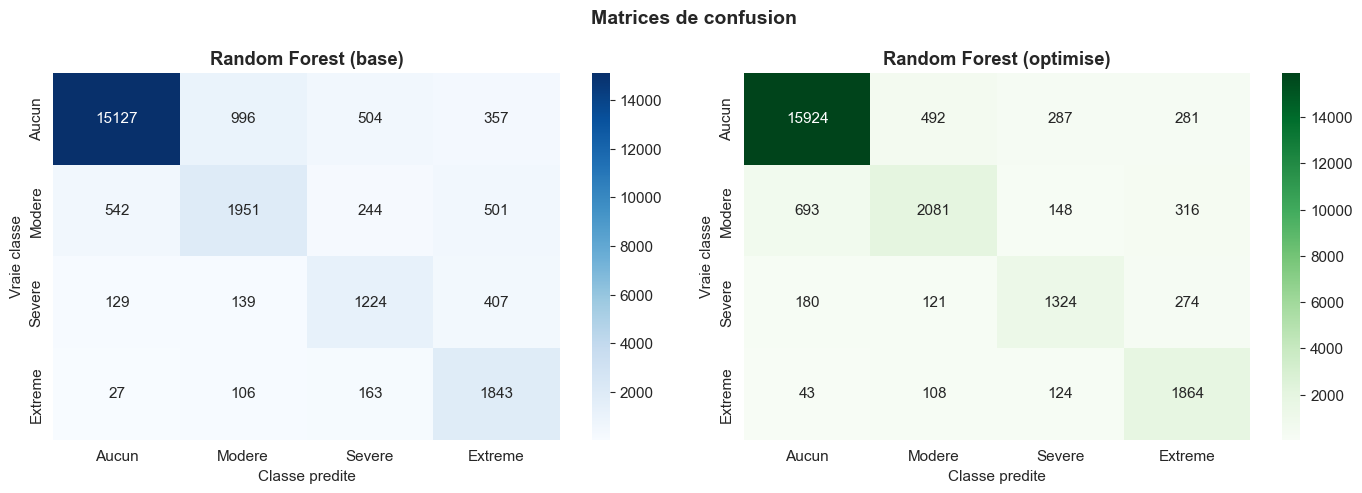

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
class_names = ['Aucun', 'Modere', 'Severe', 'Extreme']

# Random Forest de base
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Random Forest (base)')
axes[0].set_ylabel('Vraie classe')
axes[0].set_xlabel('Classe predite')

# Modele optimise
cm_best = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Random Forest (optimise)')
axes[1].set_ylabel('Vraie classe')
axes[1].set_xlabel('Classe predite')

plt.suptitle('Matrices de confusion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 10. 🔍 Importance des features

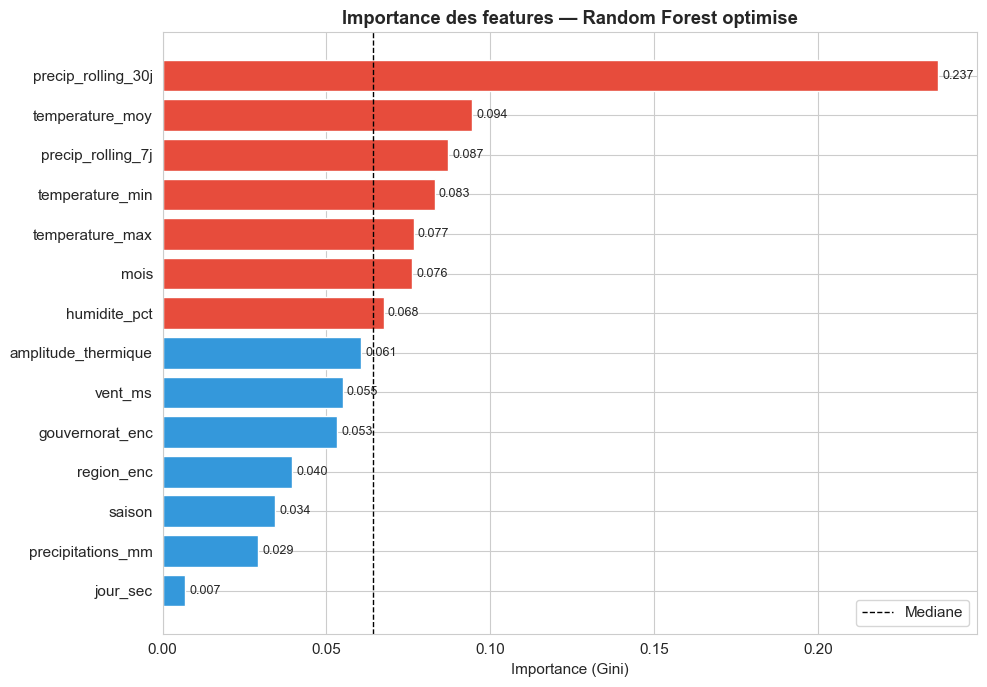

Top 5 features les plus importantes :
precip_rolling_30j    0.236687
temperature_moy       0.094499
precip_rolling_7j     0.087067
temperature_min       0.083000
temperature_max       0.076577
dtype: float64


In [18]:
importances = pd.Series(best_model.feature_importances_, index=FEATURES)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
colors_imp = ['#e74c3c' if v > importances.median() else '#3498db'
              for v in importances.values]
bars = ax.barh(importances.index, importances.values, color=colors_imp)
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_xlabel('Importance (Gini)')
ax.set_title('Importance des features — Random Forest optimise')
ax.axvline(importances.median(), color='black', linestyle='--',
           linewidth=1, label='Mediane')
ax.legend()
plt.tight_layout()
plt.savefig('../data/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 5 features les plus importantes :')
print(importances.sort_values(ascending=False).head())

---
## 11. 💾 Sauvegarde du meilleur modèle

In [19]:
joblib.dump(best_model, '../models/best_model.pkl')
joblib.dump(FEATURES,   '../models/features.pkl')

print('Modele sauvegarde dans models/best_model.pkl')
print('Features sauvegardees dans models/features.pkl')
print('Scaler sauvegarde dans models/scaler.pkl')
print('\nFichiers disponibles dans models/ :')
for f in os.listdir('../models'):
    size = os.path.getsize(f'../models/{f}') / 1024
    print(f'  {f} ({size:.1f} KB)')

Modele sauvegarde dans models/best_model.pkl
Features sauvegardees dans models/features.pkl
Scaler sauvegarde dans models/scaler.pkl

Fichiers disponibles dans models/ :
  best_model.pkl (278361.2 KB)
  features.pkl (0.2 KB)
  le_gouvernorat.pkl (0.7 KB)
  le_region.pkl (0.5 KB)
  scaler.pkl (1.4 KB)


---
## 12. ✅ Conclusion

In [20]:
print('=' * 60)
print('  SYNTHESE DE LA MODELISATION')
print('=' * 60)
print(f"""
RESULTATS DES MODELES
  Logistic Regression : Accuracy={acc_lr:.3f} | F1={f1_lr:.3f}
  Decision Tree       : Accuracy={acc_dt:.3f} | F1={f1_dt:.3f}
  Random Forest       : Accuracy={acc_rf:.3f} | F1={f1_rf:.3f}
  XGBoost             : Accuracy={acc_xgb:.3f} | F1={f1_xgb:.3f}
  RF Optimise         : Accuracy={acc_best:.3f} | F1={f1_best:.3f}

MEILLEUR MODELE
  Random Forest optimise avec RandomizedSearchCV
  Meilleurs parametres : {rf_search.best_params_}

FEATURES LES PLUS IMPORTANTES
  {importances.sort_values(ascending=False).head(3).index.tolist()}

PREPROCESSING APPLIQUE
  - Suppression des NaN (3 premiers mois par gouvernorat)
  - Encodage LabelEncoder (region, gouvernorat)
  - Normalisation StandardScaler
  - class_weight='balanced' pour le desequilibre
  - 5 nouvelles features creees (Feature Engineering)

PROCHAINE ETAPE
  → Interface Streamlit avec carte interactive de la Tunisie
""")
print('=' * 60)

  SYNTHESE DE LA MODELISATION

RESULTATS DES MODELES
  Logistic Regression : Accuracy=0.609 | F1=0.648
  Decision Tree       : Accuracy=0.705 | F1=0.735
  Random Forest       : Accuracy=0.830 | F1=0.836
  XGBoost             : Accuracy=0.800 | F1=0.777
  RF Optimise         : Accuracy=0.874 | F1=0.873

MEILLEUR MODELE
  Random Forest optimise avec RandomizedSearchCV
  Meilleurs parametres : {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 20}

FEATURES LES PLUS IMPORTANTES
  ['precip_rolling_30j', 'temperature_moy', 'precip_rolling_7j']

PREPROCESSING APPLIQUE
  - Suppression des NaN (3 premiers mois par gouvernorat)
  - Encodage LabelEncoder (region, gouvernorat)
  - Normalisation StandardScaler
  - class_weight='balanced' pour le desequilibre
  - 5 nouvelles features creees (Feature Engineering)

PROCHAINE ETAPE
  → Interface Streamlit avec carte interactive de la Tunisie

